# Experiment 12 — Frozen transfer: higher learning rate

**Answer:** increasing LR from `1e-4` to `3e-3` substantially improves oxygen, but makes only a small change to silicon. The frozen backbone and 132 trainable parameters are unchanged. A larger LR helps this fitting recipe; it does not close the gap to full fine-tuning.

Both runs use the same data, seed, ordinary shielding MSE and 300-epoch budget. Compare the trained checkpoint from 11 (epoch 300), **not its stale exported model**, with 12's selected checkpoint (epoch 297).

In [1]:
%matplotlib inline
from pathlib import Path
import os, sys
PROJECT = Path(os.environ.get('NEQUIP_PROJECT', '/Users/louismcauliffe/code/research/NequIP_experiments'))
REVIEW_DIR = Path(os.environ.get('NMR_REVIEW_DIR', str(PROJECT / 'experiments')))
sys.path.insert(0, str(PROJECT))
from analysis_helpers.scalar_transfer_review import *
CACHE = Path(os.environ.get('NEQUIP_EVAL_OUTPUT', str(PROJECT / 'experiments/10-12-evaluation-data')))
OUTPUT = REVIEW_DIR / '12-TensorNequIP-MSIsotropy-Frozen-LR-Comparison-figures'
OUTPUT.mkdir(parents=True, exist_ok=True)
sites, metrics, structures, boot, provenance, manifest = load_review(PROJECT, CACHE)
overview(provenance, ['09', '11', '12'])
print('Verified cached predictions: 800 training + 50 validation structures; test data excluded.')


Verified cached predictions: 800 training + 50 validation structures; test data excluded.


,Selected epoch,Initial LR,Trainable parameters,Export matches checkpoint
Experiment,,,,
09,295,0.0001,738052,True
11,300,0.0001,132,False
12,297,0.0030,132,True


## 1 · Learning-rate comparison


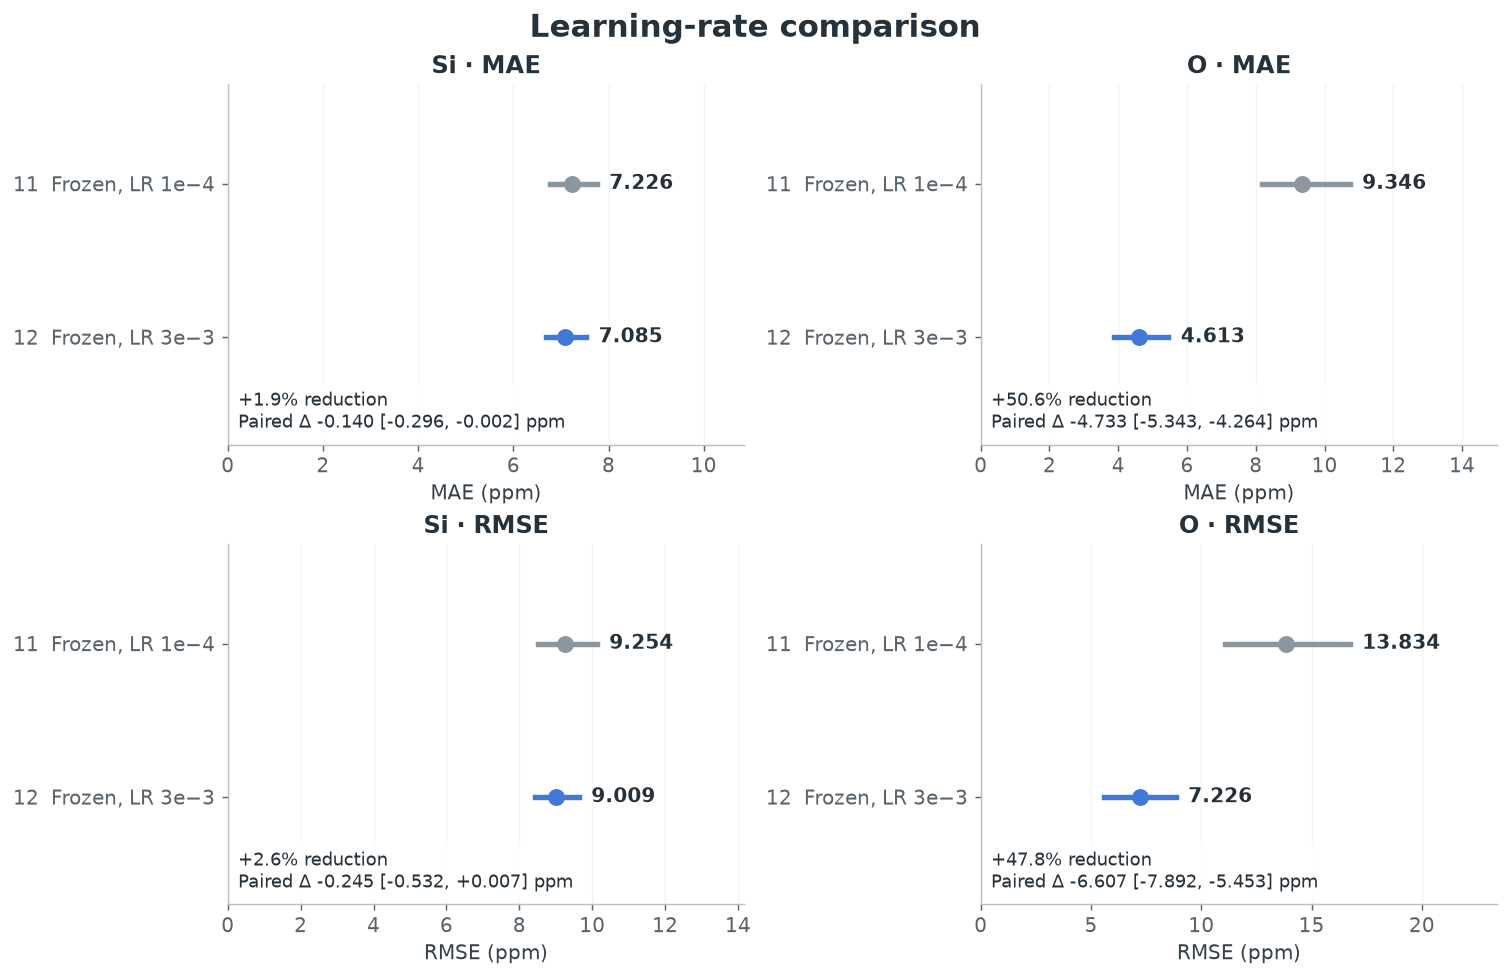

**Si MAE:** 7.226 → 7.085 ppm (1.9% reduction); paired 95% Δ [-0.296, -0.002] ppm.

**Si RMSE:** 9.254 → 9.009 ppm (2.6% reduction); paired 95% Δ [-0.532, +0.007] ppm.

**O MAE:** 9.346 → 4.613 ppm (50.6% reduction); paired 95% Δ [-5.343, -4.264] ppm.

**O RMSE:** 13.834 → 7.226 ppm (47.8% reduction); paired 95% Δ [-7.892, -5.453] ppm.

In [2]:
changes = paired_figure(metrics, boot, '11', '12', 'Learning-rate comparison', OUTPUT, '01-learning-rate-effect')
for r in changes.itertuples():
    display(Markdown(f'**{r.element} {r.metric}:** {r.old:.3f} → {r.new:.3f} ppm ({r.reduction_pct:.1f}% reduction); paired 95% Δ [{r.lower:+.3f}, {r.upper:+.3f}] ppm.'))

## 2 · Training–validation gap


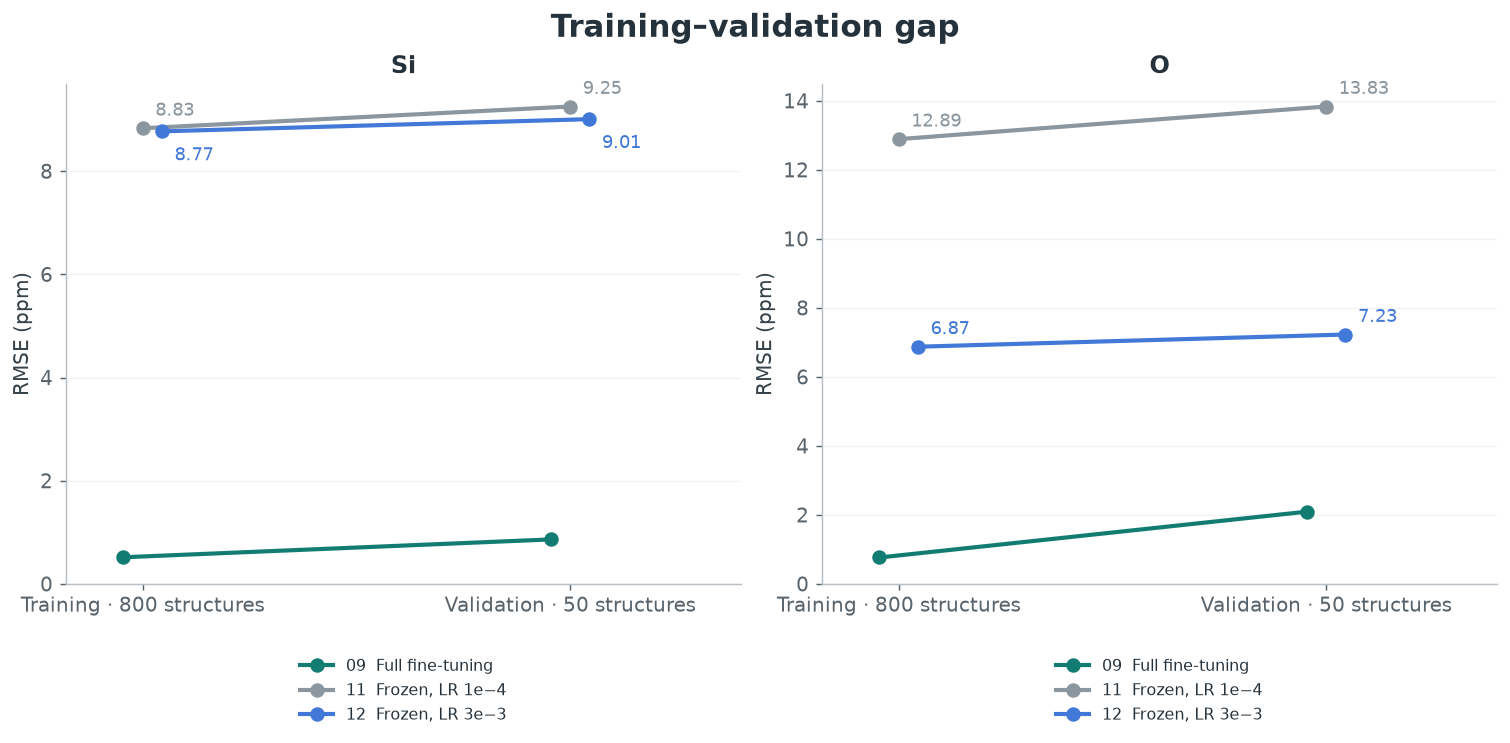

split        Training RMSE  Validation RMSE
run element                                
09  O                0.765            2.093
    Si               0.516            0.862
11  O               12.888           13.834
    Si               8.832            9.254
12  O                6.873            7.226
    Si               8.772            9.009

**Si:** experiment 12 training/validation RMSE = 8.772/9.009 ppm; full-fine-tuning validation = 0.862 ppm.

**O:** experiment 12 training/validation RMSE = 6.873/7.226 ppm; full-fine-tuning validation = 2.093 ppm.

In [3]:
gap_figure(metrics, ['09','11','12'], 'Training–validation gap', OUTPUT, '02-remaining-gap', baseline=False)
for el in ['Si','O']:
    display(Markdown(f'**{el}:** experiment 12 training/validation RMSE = {value(metrics,"12",el,split="train"):.3f}/{value(metrics,"12",el):.3f} ppm; full-fine-tuning validation = {value(metrics,"09",el):.3f} ppm.'))

## 3 · Parity


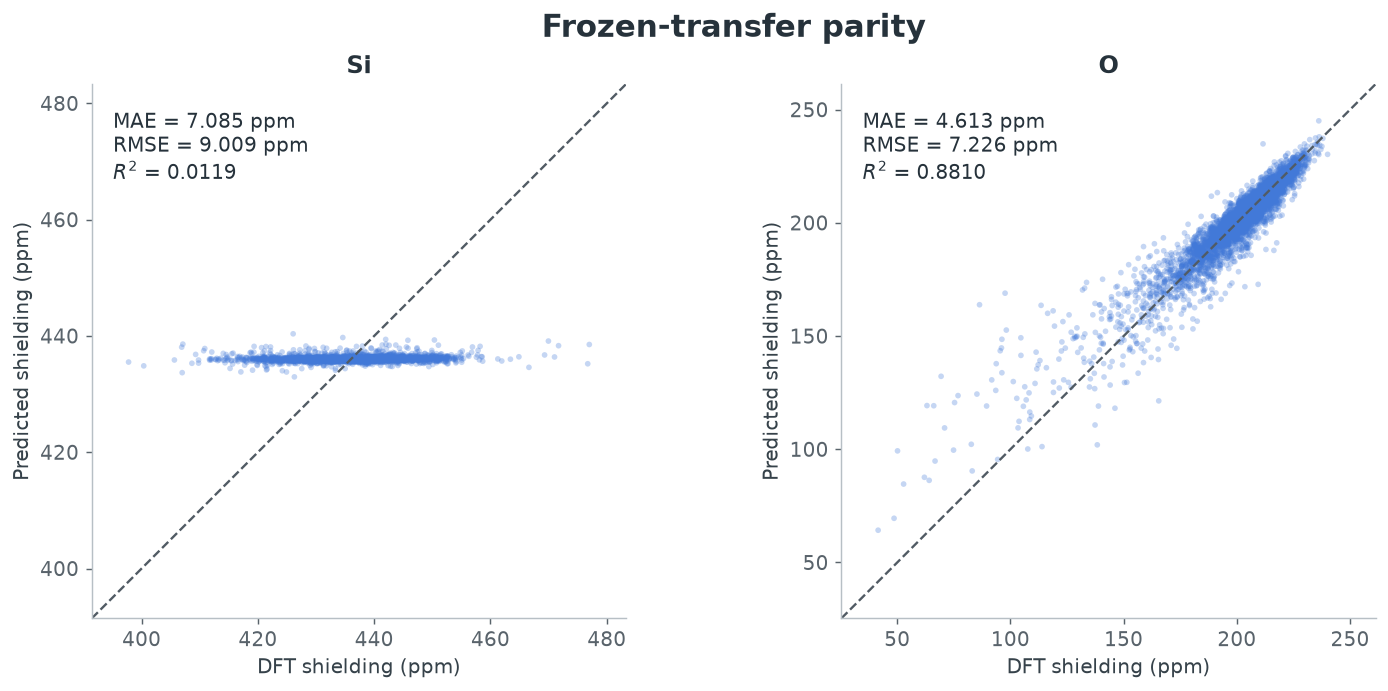

In [4]:
parity_figure(sites, '12', 'Frozen-transfer parity', OUTPUT, '03-parity')


In [5]:
metrics[metrics.run.isin(['09', '11', '12'])].to_csv(OUTPUT / 'metrics.csv', index=False)
provenance[provenance.run.isin(['09', '11', '12'])].to_csv(OUTPUT / 'provenance.csv', index=False)
(OUTPUT / 'evaluation-manifest.json').write_text(json.dumps(manifest, indent=2))
assert len(list(OUTPUT.glob('*.png'))) == 3
print('Saved three figures as PNG/PDF, metric tables and provenance.')

Saved three figures as PNG/PDF, metric tables and provenance.


**Scope.** Absolute DFT isotropic shielding in ppm; no experimental referencing. Every metric is unweighted and split by element. These 50 validation structures selected the checkpoints; they are development results, not an independent test. Paired 95% intervals use 4,000 whole-structure bootstrap resamples and assume independent structures. They do not cover seed variability, model selection or unresolved trajectory dependence. All runs use seed 42; no new training or test-set evaluation occurs here.

**Reproducibility.** The setup verifies dataset, configuration and checkpoint hashes before using the shared prediction cache. `analysis_helpers/scalar_transfer_evaluate.py` regenerates it from train/validation data if absent. The shared helper `analysis_helpers/scalar_transfer_review.py` renders the figures. Use the project's `.venv` kernel; the shared helpers are in the project’s `analysis_helpers/` folder. Full epoch histories were not included in the transferred results, so no learning curves or claims of convergence are fabricated.